### Greyscaling 

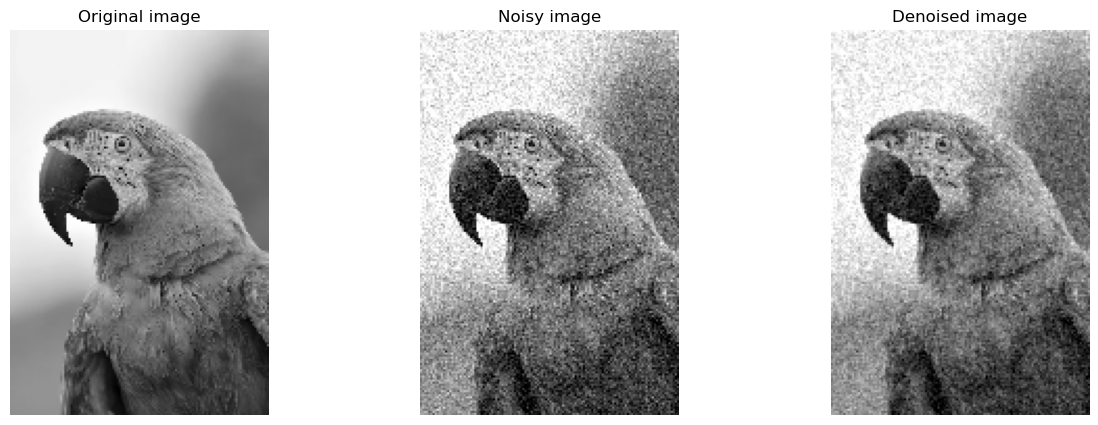

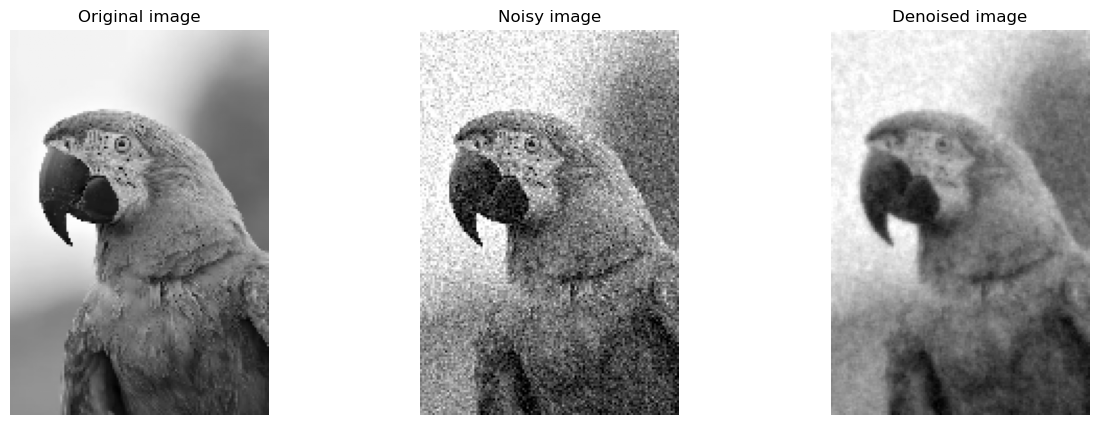

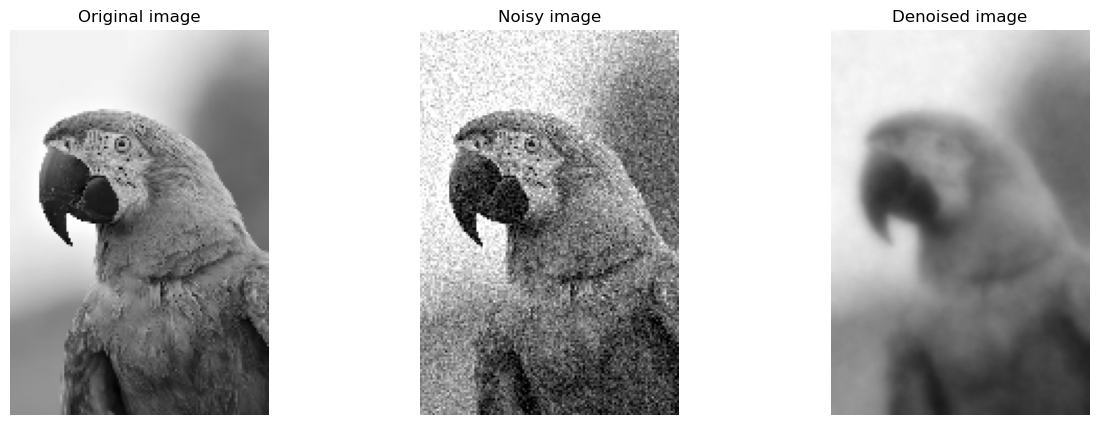

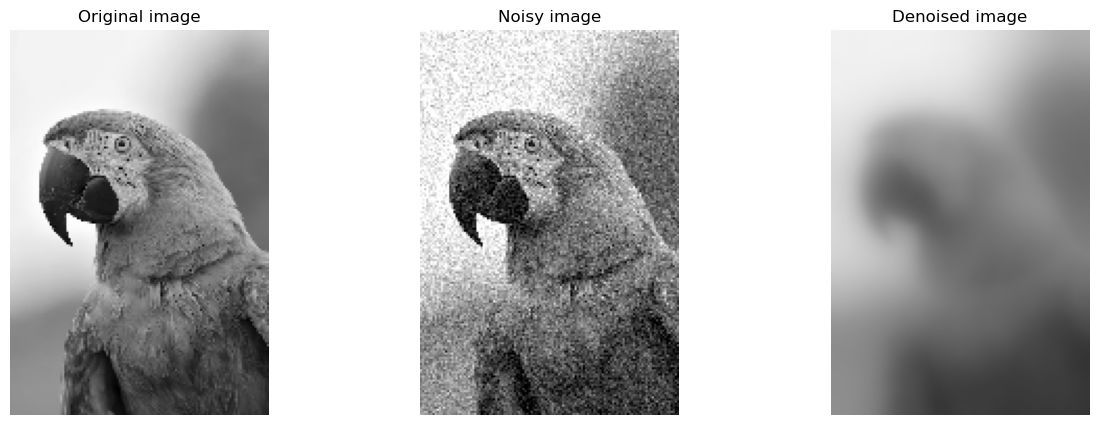

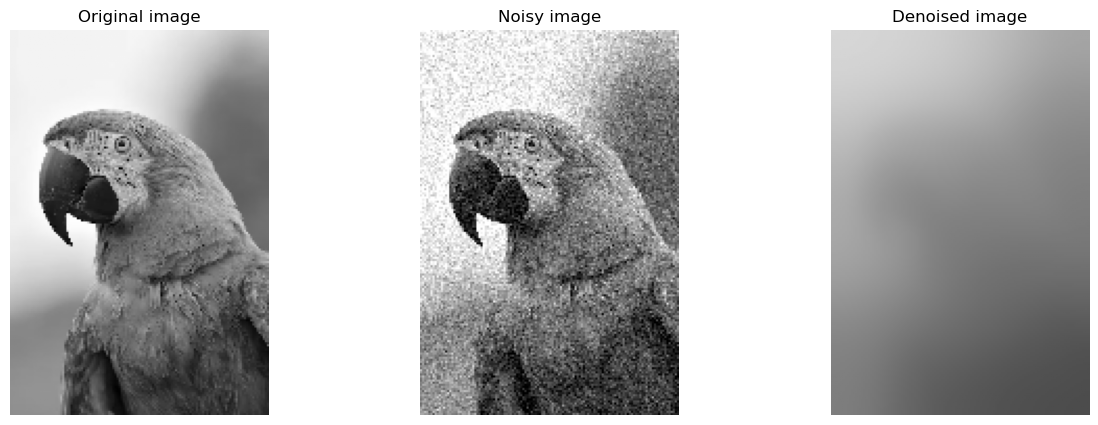

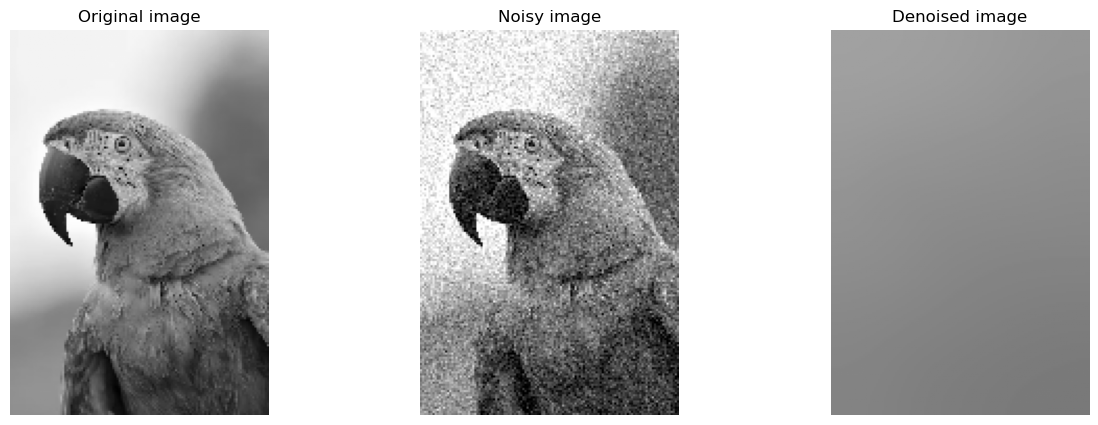

In [7]:

import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

# 1. Read image, convert to grayscale and scale to [0, 1]
image = np.asarray(Image.open("my_image.jpg").convert("RGB"), dtype=float)
B = image.mean(axis=2) / 255.0

# 2. Downsample for speed (equivalent to MATLAB B(1:4:end, 1:4:end))
B = B[::4, ::4]
m, n = B.shape

# 3. Add Gaussian noise
np.random.seed(0)  # Optional: reproducible noise
Bn = B + 0.1 * np.random.randn(m, n)

# 4. Construct the cosine matrices
def W(N):
    i = np.arange(1, N + 1)[:, None]  # Column vector: 1,...,N
    k = np.arange(N)[None, :]         # Row vector: 0,...,N-1
    return np.cos(np.pi * (i - 0.5) * k / N)

Wm = W(m)
Wm = Wm / np.linalg.norm(Wm, axis=0, keepdims=True)

Wn = W(n)
Wn = Wn / np.linalg.norm(Wn, axis=0, keepdims=True)

# 5. Construct the regularisation weights
def mu(N):
    k = np.arange(N)
    return 4 * np.sin(np.pi * k / (2 * N))**2

mu_m = mu(m)[:, None]  # Shape (m, 1)
mu_n = mu(n)[None, :]  # Shape (1, n)

# 6. Regularisation parameter

# 7. Transform, shrink and reconstruct
for lam in [0.1, 1, 10, 100, 1000, 10000]:
    Xh = (Wm.T @ Bn @ Wn) / (1 + lam * (mu_m + mu_n))
    X = Wm @ Xh @ Wn.T

    # 8. Display original, noisy and denoised images
    fig, axes = plt.subplots(1, 3, figsize=(15, 5))

    axes[0].imshow(B, cmap="gray", vmin=0, vmax=1)
    axes[0].set_title("Original image")

    axes[1].imshow(Bn, cmap="gray", vmin=0, vmax=1)
    axes[1].set_title("Noisy image")

    axes[2].imshow(np.clip(X, 0, 1), cmap="gray", vmin=0, vmax=1)
    axes[2].set_title("Denoised image")
    
    for ax in axes:
        ax.axis("off")




### As Lambda increases, the denoised image becomes blurrier. 